In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import skimage.io
import skimage.color
import skimage.filters
from skimage.transform import rescale


# Plot grijswaarden hoge resolutie afbeelding

C:\Users\morti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.8_qbz5n2kfra8p0\LocalCache\local-packages\Python38\site-packages\skimage\_shared\utils.py:338: FutureWarning: `multichannel` is a deprecated argument name for `rescale`. It will be removed in version 1.0.Please use `channel_axis` instead.
  return func(*args, **kwargs)
Lossy conversion from float64 to uint8. Range [0, 1]. Convert image to uint8 prior to saving to suppress this warning.


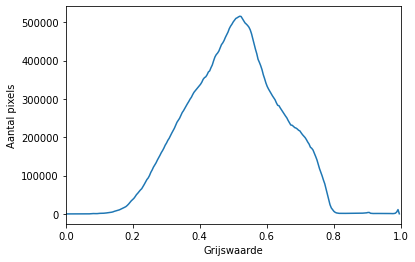

In [5]:
""" image = Image.open("./data/images/DSC00174.JPG")
print('SIZE: {0}\nMODE: {1}'.format(image.size, image.mode))

ni = np.array(image)
npfilter = ni[:,:,0]<100
Image.fromarray((npfilter*255).astype(np.uint8)).save('result.png')
print('npfilter saved as npresult.png')
edgefilter = image.convert("L").filter(ImageFilter.FIND_EDGES)
edgefilter.save('edgeresult.png')
print('edgefilter saved as edgeresult.png')
"""

img = skimage.io.imread("./data/images_full/DSC00238.JPG")
image_rescaled = rescale(img, 0.5, anti_aliasing=False, multichannel=True)
skimage.io.imsave('rescaled.JPG', image_rescaled)
img_gray = skimage.color.rgb2gray(img)
img_blur = skimage.filters.gaussian(img_gray, sigma=5)

histogram, bin_edges = np.histogram(img_blur, bins=256, range=(0.0, 1.0))
plt.plot(bin_edges[0:-1], histogram)
plt.xlabel("Grijswaarde")
plt.ylabel("Aantal pixels")
plt.xlim(0, 1.0)
plt.show()


# Onderzoek onderscheid tussen aarde, planten en gras

0.45


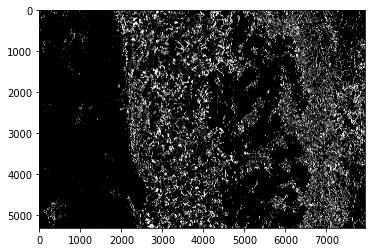

In [4]:
t = 0.45
s = 0.4
print(t)
mask = (img_blur < t) & (img_blur > s)

fig, ax = plt.subplots()
plt.imshow(mask, cmap='gray')
plt.show()

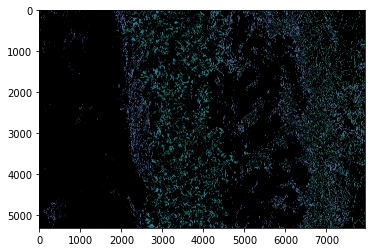

In [5]:
selection = np.zeros_like(img)
selection[mask] = img[mask]
skimage.io.imsave('result.JPG', selection)

fig, ax = plt.subplots()
plt.imshow(selection)
plt.show()

Conclusie: er is geen onderscheid mogelijk tussen aarde, gras en planten door middel van grijswaarde van pixels. Er is dus nood aan een manuele horizontale cropping om het YOLO-model efficiënter te trainen.